### RQ1-01. Experiment Directory Initialization

**Objective:** Initialize the Google Drive workspace and establish a consistent directory structure for RQ1–RQ3 and final evaluation.

**Input:** Existing project directory `Output/`.

**Processing:** Mount Google Drive, define `ROOT` and `EXP`, and create directories for model artifacts, evaluation results, figures, and deployment outputs.

**Output:** `Output/ML_Experiments/` with dedicated subdirectories for each research stage.

**Methodological note:** Directory creation does not modify the existing datasets or trained models.

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/Shareddrives/"
    "M(anchine) L(earning)/Output"
)

EXP = ROOT / "ML_Experiments"

for rq in ["RQ1", "RQ2", "RQ3"]:
    for folder in ["results", "figures"]:
        (EXP / rq / folder).mkdir(
            parents=True, exist_ok=True
        )

for rq in ["RQ1", "RQ2"]:
    (EXP / rq / "models").mkdir(
        parents=True, exist_ok=True
    )

for folder in ["model", "results", "deployment"]:
    (EXP / "Final" / folder).mkdir(
        parents=True, exist_ok=True
    )

print("Thư mục experiments:", EXP)
assert ROOT.exists()

Mounted at /content/drive
Thư mục experiments: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments


### RQ1-02. Library Imports and Reproducibility Settings

**Objective:** Initialize the software environment and establish consistent experimental settings.

**Input:** Python libraries required for data processing, model training, serialization, and performance evaluation.

**Procedure:** Import the required libraries, set `SEED = 42`, define the reference classification threshold of 0.5, and display key library versions.

**Output:** A reproducible experimental configuration shared across the three baseline models.

**Methodological consideration:** The threshold of 0.5 is used only to report threshold-dependent metrics in RQ1. Threshold optimization is reserved for RQ3.v


In [ ]:
# Nếu thiếu thư viện, chạy dòng bên dưới MỘT LẦN:
# %pip -q install xgboost pyarrow joblib

import gc
import json
import platform
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import display

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score
)

SEED = 42
THRESHOLD_REFERENCE = 0.5  # Chỉ dùng để báo cáo Precision/Recall/F1 ở RQ1, chưa tối ưu threshold
print("Python:", platform.python_version())
print("scikit-learn:", sklearn.__version__)
print("xgboost:", xgboost.__version__)
print("pandas:", pd.__version__)

Python: 3.13.18
scikit-learn: 1.6.1
xgboost: 3.4.1
pandas: 2.2.3


### RQ1-03. Dataset Paths and Output Configuration

**Objective:** Define the input datasets and output locations required for RQ1.

**Input:** Preprocessed LR and Tree Train/Validation Parquet files generated during data preparation.

**Procedure:** Assign dataset paths for each model family, initialize artifact directory references, and verify that all required input files exist.

**Output:** Validated file paths for model training and validation, along with directories for saving models, metrics, and figures.

**Methodological consideration:** Only the predefined Train (60%) and Validation (20%) partitions are used. The held-out Test (20%) partition remains excluded from RQ1.

In [ ]:
# Dùng lại ROOT, EXP đã khai báo ở RQ1-00 (không mount Drive lần hai)
PP_DIR = ROOT / "Preprocessing"
RQ1_DIR = EXP / "RQ1"
MODEL_DIR = RQ1_DIR / "models"
RESULT_DIR = RQ1_DIR / "results"
FIGURE_DIR = RQ1_DIR / "figures"

# Kiểm tra: các thư mục đã tồn tại từ cell đầu tiên
assert PP_DIR.is_dir(), f"Không tìm thấy thư mục Preprocessing: {PP_DIR}"
for folder in (MODEL_DIR, RESULT_DIR, FIGURE_DIR):
    assert folder.is_dir(), f"Chưa có thư mục: {folder}"

# RQ1 chỉ dùng Train + Validation. Không khai báo đường dẫn Test ở đây.
FILES = {
    "LR": {
        "Train": PP_DIR / "3.2.7_LR_Train_60pct.parquet",
        "Validation": PP_DIR / "3.2.7_LR_Validation_20pct.parquet",
    },
    "Tree": {
        "Train": PP_DIR / "3.2.7_Tree_Train_60pct.parquet",
        "Validation": PP_DIR / "3.2.7_Tree_Validation_20pct.parquet",
    },
}
for family, splits in FILES.items():
    for split, path in splits.items():
        print(f"{family}/{split}: {path} | tồn tại = {path.is_file()}")
        assert path.is_file(), f"Thiếu file: {path}"
print("PASS: Đã xác nhận đủ 4 file Train/Validation.")

LR/Train: /content/drive/Shareddrives/M(anchine) L(earning)/Output/Preprocessing/3.2.7_LR_Train_60pct.parquet | tồn tại = True
LR/Validation: /content/drive/Shareddrives/M(anchine) L(earning)/Output/Preprocessing/3.2.7_LR_Validation_20pct.parquet | tồn tại = True
Tree/Train: /content/drive/Shareddrives/M(anchine) L(earning)/Output/Preprocessing/3.2.7_Tree_Train_60pct.parquet | tồn tại = True
Tree/Validation: /content/drive/Shareddrives/M(anchine) L(earning)/Output/Preprocessing/3.2.7_Tree_Validation_20pct.parquet | tồn tại = True
PASS: Đã xác nhận đủ 4 file Train/Validation.


### RQ1-04. Baseline Model Configuration

**Objective:** Specify three classification algorithms for comparative evaluation under the original class distribution.

**Input:** Logistic Regression, Random Forest, and XGBoost estimators.

**Procedure:** Define fixed baseline hyperparameters, assign the appropriate preprocessing family to each estimator, and establish the execution order.

**Output:** `MODEL_CONFIGS`, containing the three baseline model specifications, and `MODELS_TO_RUN`, defining the execution sequence.

**Methodological consideration:** No class weighting or synthetic oversampling is applied in RQ1. The predefined hyperparameters provide an initial comparison rather than a claim of optimal model configuration.

In [ ]:
MODEL_CONFIGS = {
    "Logistic_Regression": {
        "family": "LR",
        "estimator": LogisticRegression(
            solver="lbfgs", max_iter=300, class_weight=None,
            random_state=SEED
        ),
    },
    "Random_Forest": {
        "family": "Tree",
        "estimator": RandomForestClassifier(
            n_estimators=100, max_depth=14, min_samples_leaf=5,
            max_samples=0.5, bootstrap=True,
            n_jobs=2, class_weight=None, random_state=SEED
        ),
    },
    "XGBoost": {
        "family": "Tree",
        "estimator": XGBClassifier(
            n_estimators=200, max_depth=6, learning_rate=0.1,
            objective="binary:logistic", eval_metric="logloss",
            tree_method="hist", n_jobs=2, random_state=SEED,
            scale_pos_weight=1.0
        ),
    },
}

# Chạy lần lượt; nếu Colab thiếu RAM, có thể đổi danh sách thành ["Logistic_Regression"]...
MODELS_TO_RUN = ["Logistic_Regression", "Random_Forest", "XGBoost"]
TARGET = "isFraud"

### RQ1-05. Data Validation and Evaluation Functions

**Objective:** Standardize data loading, integrity checks, and performance metric calculations for all baseline models.

**Input:** Preprocessed Train and Validation datasets containing 13 numerical model-input columns and the binary target `isFraud`.

**Procedure:** Verify target validity, feature dimensions, missing values, finite numerical values, schema consistency, and non-overlapping Train/Validation indices. Define a shared evaluation function for AP, ROC-AUC, Accuracy, Precision, Recall, F1-score, and confusion-matrix counts.

**Output:** Reusable `load_family()` and `evaluate_on_validation()` functions.

**Methodological consideration:** AP and ROC-AUC are calculated using continuous model scores. Precision, Recall, F1-score, and confusion-matrix counts are calculated at the reference threshold of 0.5.

In [ ]:
def load_family(family):
    train_df = pd.read_parquet(FILES[family]["Train"])
    val_df = pd.read_parquet(FILES[family]["Validation"])

    for split_name, df in (("Train", train_df), ("Validation", val_df)):
        assert TARGET in df.columns, f"{family}/{split_name}: thiếu cột {TARGET}"
        assert df.index.is_unique, f"{family}/{split_name}: index không duy nhất"
        assert df[TARGET].isin([0, 1]).all(), f"{family}/{split_name}: nhãn ngoài 0,1"
        features = df.drop(columns=[TARGET])
        assert features.shape[1] == 13, f"{family}/{split_name}: dự kiến 13 features"
        assert not features.isna().any().any(), f"{family}/{split_name}: có missing"
        assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in features.dtypes), "Feature chưa phải numeric"
        assert np.isfinite(features.to_numpy(dtype=np.float64, copy=False)).all(), f"{family}/{split_name}: có inf"

    assert train_df.columns.equals(val_df.columns), f"{family}: schema Train/Validation khác nhau"
    assert train_df.index.intersection(val_df.index).empty, f"{family}: Train/Validation chồng index"
    X_train, y_train = train_df.drop(columns=[TARGET]), train_df[TARGET].astype("int8")
    X_val, y_val = val_df.drop(columns=[TARGET]), val_df[TARGET].astype("int8")
    assert y_train.nunique() == 2 and y_val.nunique() == 2, "Thiếu một lớp target"

    print(f"{family}: Train {X_train.shape}, Validation {X_val.shape}")
    print(f"Fraud Train: {int(y_train.sum()):,}; Fraud Validation: {int(y_val.sum()):,}")
    # Giữ lại DataFrame đúng kiểu dữ liệu gốc. Không ép tất cả sang float64 để tránh tăng RAM.
    return X_train, y_train, X_val, y_val


def evaluate_on_validation(y_true, scores, threshold=0.5):
    # AP và ROC-AUC dùng điểm dự đoán liên tục; các metrics còn lại dùng threshold tham chiếu.
    labels = (np.asarray(scores) >= threshold).astype("int8")
    tn, fp, fn, tp = confusion_matrix(y_true, labels, labels=[0, 1]).ravel()
    return {
        "AP": float(average_precision_score(y_true, scores)),
        "ROC_AUC": float(roc_auc_score(y_true, scores)),
        "Accuracy": float(accuracy_score(y_true, labels)),
        "Precision_at_0_5": float(precision_score(y_true, labels, zero_division=0)),
        "Recall_at_0_5": float(recall_score(y_true, labels, zero_division=0)),
        "F1_at_0_5": float(f1_score(y_true, labels, zero_division=0)),
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
    }

### RQ1-06. Model Training and Validation Evaluation

**Objective:** Train and evaluate Logistic Regression, Random Forest, and XGBoost using a consistent experimental protocol.

**Input:** Predefined baseline estimators and their corresponding Train/Validation datasets.

**Procedure:** Fit each model exclusively on Train data, generate fraud scores on Validation, calculate evaluation metrics, and save each completed model and its results. Release unused objects to reduce memory consumption between training runs.

**Output:** Three trained model artifacts (`.joblib`), model-specific metric files (`.json`), indexed Validation score files (`.parquet`), and the consolidated `rq1_comparison.csv`.

**Methodological consideration:** Model comparison is based on Validation performance. The held-out Test partition is not accessed. Model artifacts are saved after each completed run to support recovery from Colab interruptions.

In [ ]:
summary_path = RESULT_DIR / "rq1_comparison.csv"

for model_name in MODELS_TO_RUN:
    family = MODEL_CONFIGS[model_name]["family"]
    model = clone(MODEL_CONFIGS[model_name]["estimator"])  # Mỗi lượt lấy model chưa fit, không giữ model lớn trong biến cấu hình
    print(f"\n========== {model_name} ({family}) ==========")

    X_train, y_train, X_val, y_val = load_family(family)
    started = time.perf_counter()
    model.fit(X_train, y_train)  # Chỉ Train được dùng để học
    train_seconds = time.perf_counter() - started
    scores = model.predict_proba(X_val)[:, 1]

    metrics = evaluate_on_validation(y_val, scores, THRESHOLD_REFERENCE)
    row = {
        "Model": model_name,
        "Family": family,
        "Train_Rows": int(len(y_train)),
        "Validation_Rows": int(len(y_val)),
        "Fraud_Train": int(y_train.sum()),
        "Fraud_Validation": int(y_val.sum()),
        "Train_Seconds": round(float(train_seconds), 2),
        **metrics,
    }

    # (1) Lưu model. Không lưu test metrics hoặc dùng test để chọn model.
    model_path = MODEL_DIR / f"{model_name}.joblib"
    joblib.dump(model, model_path)

    # (2) Lưu scores đúng index validation, kèm nhãn để đối chiếu sau.
    score_path = RESULT_DIR / f"{model_name}_validation_scores.parquet"
    score_df = pd.DataFrame({
        "fraud_score": np.asarray(scores, dtype=np.float64),
        "isFraud": y_val.to_numpy(dtype=np.int8),
    }, index=X_val.index)
    score_df.to_parquet(score_path, index=True)

    # (3) Ghi riêng một JSON cho từng model: mất kết nối Colab vẫn giữ kết quả.
    with open(RESULT_DIR / f"{model_name}_metrics.json", "w", encoding="utf-8") as f:
        json.dump(row, f, ensure_ascii=False, indent=2)

    # (4) Gộp lại bảng so sánh nếu có các model chạy từ lần trước.
    rows = []
    for p in sorted(RESULT_DIR.glob("*_metrics.json")):
        with open(p, encoding="utf-8") as f:
            rows.append(json.load(f))
    comparison = pd.DataFrame(rows).sort_values("AP", ascending=False)
    comparison.to_csv(summary_path, index=False)

    print("AP =", round(row["AP"], 6), "| F1@0.5 =", round(row["F1_at_0_5"], 6))
    print("Đã lưu:", model_path.name, score_path.name)

    # Giải phóng RAM trước khi nạp Parquet khác
    del X_train, y_train, X_val, y_val, scores, score_df, model, comparison
    gc.collect()

print("\n✅ Đã chạy xong các mô hình trong MODELS_TO_RUN.")


========== Logistic_Regression (LR) ==========
LR: Train (3817572, 13), Validation (1272524, 13)
Fraud Train: 4,928; Fraud Validation: 1,643
AP = 0.606986 | F1@0.5 = 0.575795
Đã lưu: Logistic_Regression.joblib Logistic_Regression_validation_scores.parquet

========== Random_Forest (Tree) ==========
Tree: Train (3817572, 13), Validation (1272524, 13)
Fraud Train: 4,928; Fraud Validation: 1,643
AP = 0.996064 | F1@0.5 = 0.996947
Đã lưu: Random_Forest.joblib Random_Forest_validation_scores.parquet

========== XGBoost (Tree) ==========
Tree: Train (3817572, 13), Validation (1272524, 13)
Fraud Train: 4,928; Fraud Validation: 1,643
AP = 0.997863 | F1@0.5 = 0.997561
Đã lưu: XGBoost.joblib XGBoost_validation_scores.parquet

✅ Đã chạy xong các mô hình trong MODELS_TO_RUN.


### RQ1-07. Experiment Metadata and Reproducibility

**Objective:** Document the experimental environment and model configurations to support traceability and reproducibility.

**Input:** Random seed, dataset paths, estimator hyperparameters, and installed software versions.

**Procedure:** Collect relevant experiment metadata and serialize the information in JSON format.

**Output:** `RQ1/results/rq1_environment.json`.

**Methodological consideration:** The metadata records the intended experimental configuration. It does not independently verify model performance or guarantee identical results across different computational environments.

In [ ]:
environment = {
    "seed": SEED,
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "xgboost": xgboost.__version__,
    "test_used_in_RQ1": False,
    "dataset_input": {family: {split: str(path) for split, path in paths.items()} for family, paths in FILES.items()},
    "estimators": {name: str(config["estimator"].get_params()) for name, config in MODEL_CONFIGS.items()},
}
with open(RESULT_DIR / "rq1_environment.json", "w", encoding="utf-8") as f:
    json.dump(environment, f, ensure_ascii=False, indent=2)
print("✅ Đã lưu cấu hình:", RESULT_DIR / "rq1_environment.json")

✅ Đã lưu cấu hình: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/results/rq1_environment.json


RQ1-08. Validation Results Loading and Consistency Verification

**Objective:** Prepare and validate the saved RQ1 results for comparative visualization.

**Input: **rq1_comparison.csv and the three model-specific Validation score files.

**Procedure:** Load evaluation results, verify score ranges and binary labels, align records by transaction index, and ensure that all models are compared against the same Validation observations.

**Output:** comparison, score_tables, reference_labels, and other visualization-ready variables.

Methodological consideration: **bold text** Transaction alignment is based on preserved indices rather than row position.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve, roc_curve, average_precision_score,
    roc_auc_score, confusion_matrix
)
from IPython.display import display

# Nếu chạy riêng notebook visualization, tự kết nối Drive.
if "RESULT_DIR" not in globals() or "FIGURE_DIR" not in globals():
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/Shareddrives/M(anchine) L(earning)/Output")
    EXP = ROOT / "ML_Experiments"
    RESULT_DIR = EXP / "RQ1" / "results"
    FIGURE_DIR = EXP / "RQ1" / "figures"

RESULT_DIR = Path(RESULT_DIR)
FIGURE_DIR = Path(FIGURE_DIR)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
assert RESULT_DIR.is_dir(), f"Không tìm thấy thư mục kết quả: {RESULT_DIR}"

MODEL_NAMES = ["Logistic_Regression", "Random_Forest", "XGBoost"]
SHORT_NAMES = {
    "Logistic_Regression": "Logistic Regression",
    "Random_Forest": "Random Forest",
    "XGBoost": "XGBoost",
}

comparison_path = RESULT_DIR / "rq1_comparison.csv"
assert comparison_path.is_file(), f"Thiếu bảng so sánh: {comparison_path}"
comparison = pd.read_csv(comparison_path)
assert comparison["Model"].is_unique, "Tên model bị lặp trong bảng metrics"
assert set(MODEL_NAMES).issubset(comparison["Model"]), "Chưa đủ metrics của 3 model"
comparison = comparison.set_index("Model").loc[MODEL_NAMES].reset_index()

score_tables = {}
reference_index = None
reference_labels = None
for name in MODEL_NAMES:
    path = RESULT_DIR / f"{name}_validation_scores.parquet"
    assert path.is_file(), f"Thiếu file: {path}"
    df = pd.read_parquet(path)
    assert {"fraud_score", "isFraud"}.issubset(df.columns), f"Thiếu cột ở {path.name}"
    assert df.index.is_unique, f"Index không duy nhất: {path.name}"
    assert df["isFraud"].isin([0, 1]).all(), f"Nhãn không hợp lệ: {path.name}"
    scores = df["fraud_score"].to_numpy(dtype=float)
    assert np.isfinite(scores).all(), f"Score có NaN/Inf: {path.name}"
    assert np.logical_and(scores >= 0, scores <= 1).all(), f"Score ngoài [0,1]: {path.name}"
    if reference_index is None:
        reference_index = df.index
        reference_labels = df["isFraud"].astype(int)
    else:
        assert df.index.is_unique and df.index.difference(reference_index).empty, f"Index khác nhau: {path.name}"
        assert len(df) == len(reference_index), f"Số dòng khác nhau: {path.name}"
        df = df.reindex(reference_index)  # Căn theo index, KHÔNG dựa vào vị trí dòng
        assert np.array_equal(df["isFraud"].to_numpy(), reference_labels.to_numpy()), f"Nhãn không khớp theo index: {path.name}"
    score_tables[name] = df
    print(f"PASS {name}: {len(df):,} Validation scores")

assert reference_labels.nunique() == 2, "Validation phải có đủ 2 lớp"
print("\nĐã đối chiếu đầy đủ index và target của 3 mô hình")
print("Output figures:", FIGURE_DIR)
display(comparison[["Model", "AP", "ROC_AUC", "Precision_at_0_5", "Recall_at_0_5", "F1_at_0_5"]])

PASS Logistic_Regression: 1,272,524 Validation scores
PASS Random_Forest: 1,272,524 Validation scores
PASS XGBoost: 1,272,524 Validation scores

Đã đối chiếu đầy đủ index và target của 3 mô hình
Output figures: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/figures


,Model,AP,ROC_AUC,Precision_at_0_5,Recall_at_0_5,F1_at_0_5
0,Logistic_Regression,0.606986,0.981857,0.895887,0.424224,0.575795
1,Random_Forest,0.996064,0.999735,1.000000,0.993914,0.996947
2,XGBoost,0.997863,0.999920,0.999389,0.995740,0.997561


Mounted at /content/drive
LOGISTIC REGRESSION — VALIDATION DATA
Total transactions : 1,272,524
Fraud transactions : 1,643
Fraud prevalence   : 0.1291%
Threshold          : 0.5
Output directory   : /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/figures


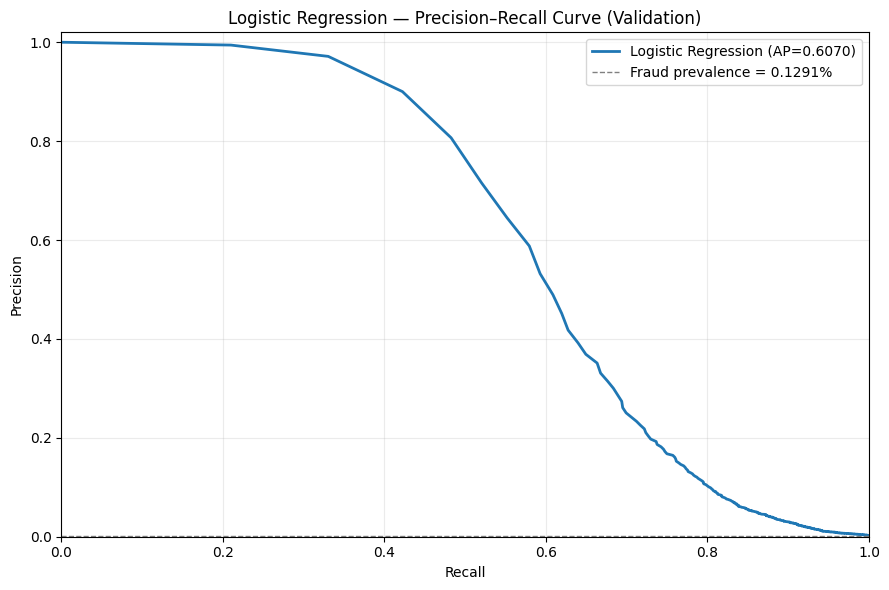

Saved: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/figures/Logistic_Regression_PR_Curve.png


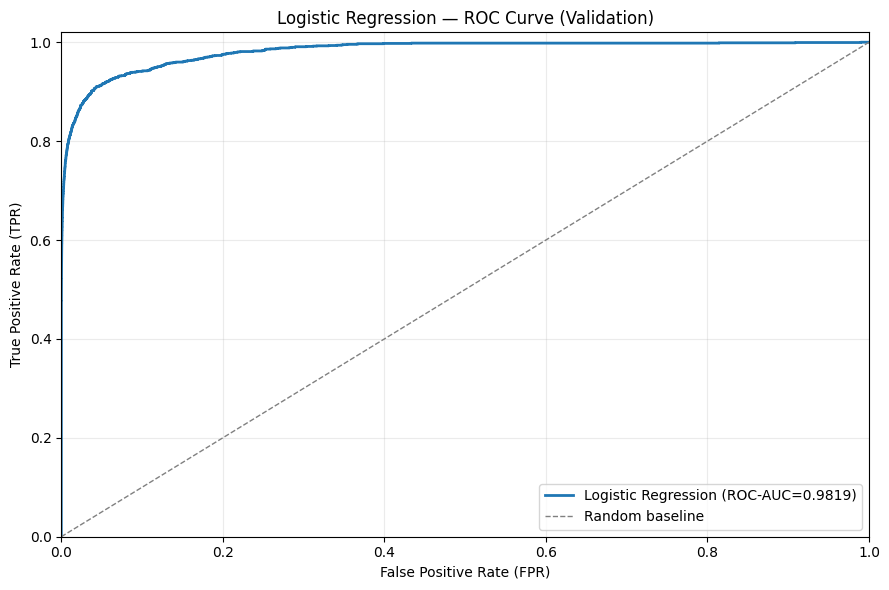

Saved: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/figures/Logistic_Regression_ROC_Curve.png

CONFUSION MATRIX AUDIT
----------------------------------------
TN = 1,270,800
FP = 81
FN = 946
TP = 697


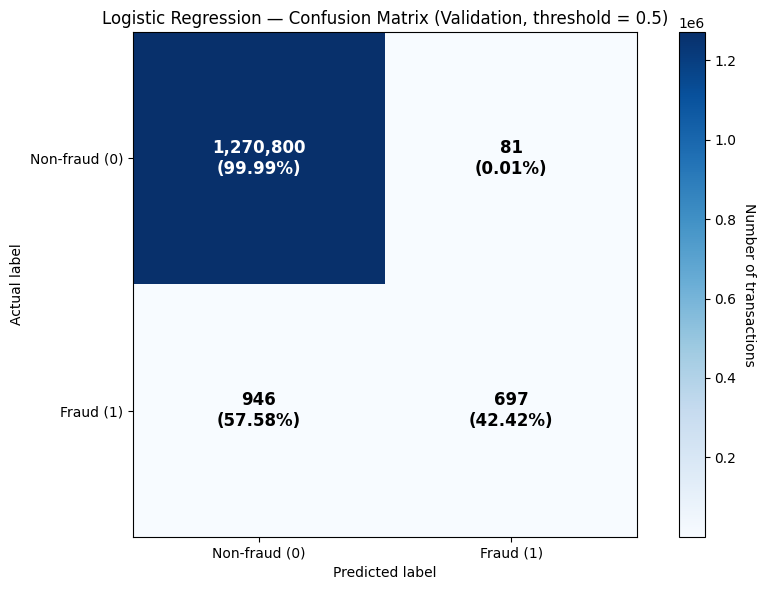

Saved: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/figures/Logistic_Regression_Confusion_Matrix.png

LOGISTIC REGRESSION — VISUALIZATION COMPLETED
AP       : 0.6069855349
ROC-AUC  : 0.9818574693

Confusion Matrix:
[[1270800      81]
 [    946     697]]

Generated figures:
 - Logistic_Regression_Confusion_Matrix.png (80.50 KB)
 - Logistic_Regression_PR_Curve.png (80.79 KB)
 - Logistic_Regression_ROC_Curve.png (90.66 KB)

All figures exported successfully.


In [1]:

# ============================================================
# RQ1 — LOGISTIC REGRESSION VISUALIZATION
# Precision-Recall Curve | ROC Curve | Confusion Matrix
# Validation set — Threshold = 0.5
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    roc_curve,
    roc_auc_score,
    confusion_matrix
)

from google.colab import drive

# ------------------------------------------------------------
# 1. MOUNT GOOGLE DRIVE
# ------------------------------------------------------------

drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments"
)

RESULT_DIR = BASE_DIR / "RQ1" / "results"
FIGURE_DIR = BASE_DIR / "RQ1" / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

SCORE_PATH = (
    RESULT_DIR / "Logistic_Regression_validation_scores.parquet"
)

# ------------------------------------------------------------
# 2. LOAD SAVED VALIDATION SCORES
# ------------------------------------------------------------

assert SCORE_PATH.is_file(), f"Không tìm thấy file: {SCORE_PATH}"

df = pd.read_parquet(SCORE_PATH)

required_columns = {"fraud_score", "isFraud"}

assert required_columns.issubset(df.columns), (
    f"Thiếu các cột: {required_columns - set(df.columns)}"
)

assert df.index.is_unique, "Validation index không duy nhất"

y_true = df["isFraud"].to_numpy(dtype=int)
y_score = df["fraud_score"].to_numpy(dtype=float)

assert np.isfinite(y_score).all(), "Score chứa NaN hoặc Inf"
assert np.logical_and(y_score >= 0, y_score <= 1).all()
assert set(np.unique(y_true)) == {0, 1}

# Reference threshold
THRESHOLD = 0.5

# Logistic Regression color: tab:blue (#1f77b4)
MODEL_COLOR = "#1f77b4"

# Calculate fraud prevalence from actual validation labels
fraud_rate = float(y_true.mean())

print("=" * 60)
print("LOGISTIC REGRESSION — VALIDATION DATA")
print("=" * 60)
print(f"Total transactions : {len(y_true):,}")
print(f"Fraud transactions : {int(y_true.sum()):,}")
print(f"Fraud prevalence   : {fraud_rate:.4%}")
print(f"Threshold          : {THRESHOLD}")
print(f"Output directory   : {FIGURE_DIR}")

# ------------------------------------------------------------
# 3. HELPER FUNCTION: DISPLAY INDICES
# ------------------------------------------------------------

def display_indices(n, max_points=6000):
    """
    Giữ điểm đầu/cuối và lấy đều các điểm để giảm
    dung lượng ảnh mà không thay đổi kết quả tính metric.
    """
    if n <= max_points:
        return np.arange(n)

    return np.unique(
        np.r_[
            0,
            np.linspace(0, n - 1, max_points).astype(int),
            n - 1
        ]
    )

# ------------------------------------------------------------
# 4. PRECISION-RECALL CURVE
# ------------------------------------------------------------

precision, recall, _ = precision_recall_curve(
    y_true,
    y_score
)

# AP is calculated using ALL validation observations
ap = average_precision_score(y_true, y_score)

# Reduce points ONLY for visualization
idx = display_indices(len(recall), max_points=6000)

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    recall[idx],
    precision[idx],
    color=MODEL_COLOR,
    linewidth=2,
    label=f"Logistic Regression (AP={ap:.4f})"
)

# Fraud prevalence baseline
ax.axhline(
    fraud_rate,
    color="gray",
    linestyle="--",
    linewidth=1,
    label=f"Fraud prevalence = {fraud_rate:.4%}"
)

ax.set(
    xlabel="Recall",
    ylabel="Precision",
    title="Logistic Regression — Precision–Recall Curve (Validation)",
    xlim=(0, 1),
    ylim=(0, 1.02)
)

ax.grid(alpha=0.25)
ax.legend(loc="best")

fig.tight_layout()

out = FIGURE_DIR / "Logistic_Regression_PR_Curve.png"

fig.savefig(
    out,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", out)

# ------------------------------------------------------------
# 5. ROC CURVE
# ------------------------------------------------------------

fpr, tpr, _ = roc_curve(
    y_true,
    y_score
)

# ROC-AUC is calculated using ALL validation observations
roc_auc = roc_auc_score(y_true, y_score)

# Reduce points ONLY for visualization
idx = display_indices(len(fpr), max_points=6000)

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    fpr[idx],
    tpr[idx],
    color=MODEL_COLOR,
    linewidth=2,
    label=f"Logistic Regression (ROC-AUC={roc_auc:.4f})"
)

# Random baseline
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1,
    label="Random baseline"
)

ax.set(
    xlabel="False Positive Rate (FPR)",
    ylabel="True Positive Rate (TPR)",
    title="Logistic Regression — ROC Curve (Validation)",
    xlim=(0, 1),
    ylim=(0, 1.02)
)

ax.grid(alpha=0.25)
ax.legend(loc="best")

fig.tight_layout()

out = FIGURE_DIR / "Logistic_Regression_ROC_Curve.png"

fig.savefig(
    out,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", out)

# ------------------------------------------------------------
# 6. CONFUSION MATRIX — THRESHOLD = 0.5
# ------------------------------------------------------------

y_pred = (y_score >= THRESHOLD).astype(int)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

# Row-normalized confusion matrix
cm_normalized = cm.astype(float) / cm.sum(
    axis=1,
    keepdims=True
)

# Verify expected results against saved metrics
tn, fp, fn, tp = cm.ravel()

print("\nCONFUSION MATRIX AUDIT")
print("-" * 40)
print(f"TN = {tn:,}")
print(f"FP = {fp:,}")
print(f"FN = {fn:,}")
print(f"TP = {tp:,}")

# ------------------------------------------------------------
# 7. PLOT CONFUSION MATRIX
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

im = ax.imshow(
    cm,
    interpolation="nearest",
    cmap=plt.cm.Blues
)

# Colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.ax.set_ylabel(
    "Number of transactions",
    rotation=-90,
    va="bottom"
)

classes = ["Non-fraud (0)", "Fraud (1)"]

ax.set(
    xticks=np.arange(2),
    yticks=np.arange(2),
    xticklabels=classes,
    yticklabels=classes,
    xlabel="Predicted label",
    ylabel="Actual label",
    title=(
        "Logistic Regression — Confusion Matrix "
        "(Validation, threshold = 0.5)"
    )
)

# Annotate each cell with:
# Absolute count + row-normalized percentage

threshold_color = cm.max() / 2.0

for i in range(2):
    for j in range(2):

        count = cm[i, j]
        percentage = cm_normalized[i, j] * 100

        text_color = (
            "white" if count > threshold_color else "black"
        )

        ax.text(
            j,
            i,
            f"{count:,}\n({percentage:.2f}%)",
            ha="center",
            va="center",
            color=text_color,
            fontsize=12,
            fontweight="bold"
        )

fig.tight_layout()

out = FIGURE_DIR / "Logistic_Regression_Confusion_Matrix.png"

fig.savefig(
    out,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", out)

# ------------------------------------------------------------
# 8. FINAL VERIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("LOGISTIC REGRESSION — VISUALIZATION COMPLETED")
print("=" * 60)

print(f"AP       : {ap:.10f}")
print(f"ROC-AUC  : {roc_auc:.10f}")

print("\nConfusion Matrix:")
print(cm)

print("\nGenerated figures:")

for path in sorted(FIGURE_DIR.glob("Logistic_Regression_*.png")):
    print(f" - {path.name} ({path.stat().st_size / 1024:.2f} KB)")

assert len(
    list(FIGURE_DIR.glob("Logistic_Regression_*.png"))
) >= 3, "Chưa xuất đủ 3 biểu đồ."

print("\nAll figures exported successfully.")


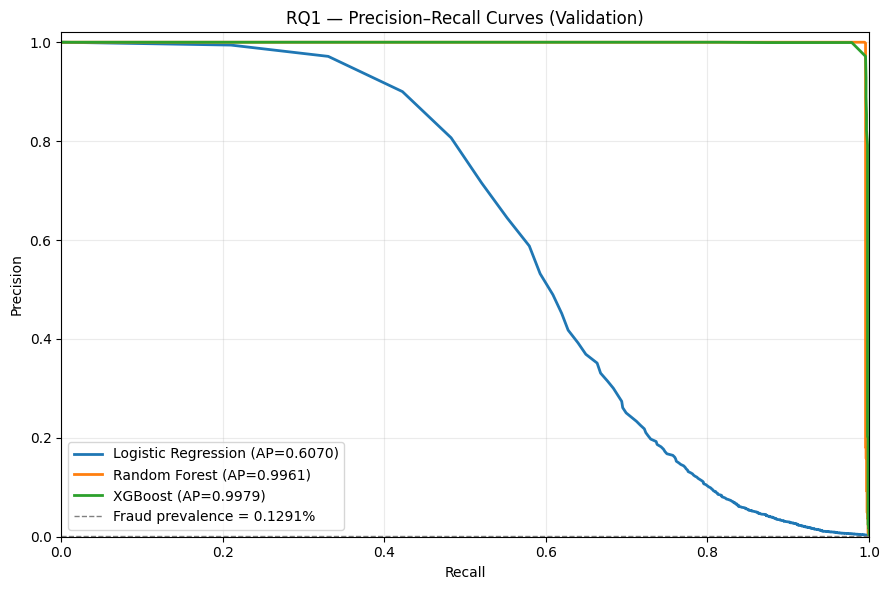

Đã lưu: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/figures/rq1_pr_curves.png


In [ ]:
def display_indices(n, max_points=6000):
    """Giữ điểm đầu/cuối và lấy đều các điểm để chỉ giảm độ nặng của hình."""
    if n <= max_points:
        return np.arange(n)
    return np.unique(np.r_[0, np.linspace(0, n - 1, max_points).astype(int), n - 1])

y_true = reference_labels.to_numpy(dtype=int)
fig, ax = plt.subplots(figsize=(9, 6))
for name in MODEL_NAMES:
    scores = score_tables[name]["fraud_score"].to_numpy(dtype=float)
    precision, recall, _ = precision_recall_curve(y_true, scores)
    ap = average_precision_score(y_true, scores)  # Tính bằng toàn bộ dữ liệu
    idx = display_indices(len(recall))
    ax.plot(recall[idx], precision[idx], linewidth=2, label=f"{SHORT_NAMES[name]} (AP={ap:.4f})")

fraud_rate = float(y_true.mean())
ax.axhline(fraud_rate, color="gray", linestyle="--", linewidth=1,
           label=f"Fraud prevalence = {fraud_rate:.4%}")
ax.set(xlabel="Recall", ylabel="Precision", title="RQ1 — Precision–Recall Curves (Validation)", xlim=(0, 1), ylim=(0, 1.02))
ax.grid(alpha=0.25)
ax.legend(loc="best")
fig.tight_layout()
out = FIGURE_DIR / "rq1_pr_curves.png"
fig.savefig(out, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Đã lưu:", out)

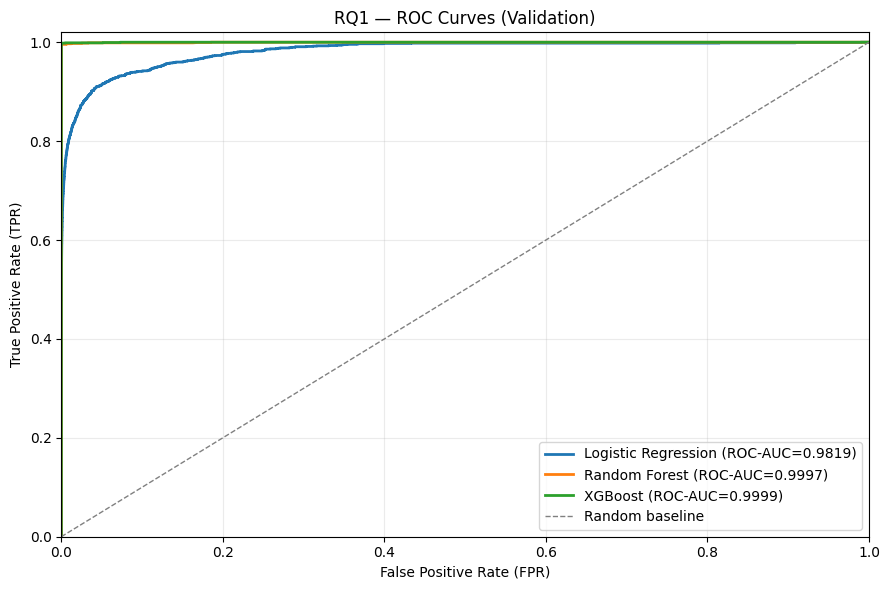

Đã lưu: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/figures/rq1_roc_curves.png


In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
for name in MODEL_NAMES:
    scores = score_tables[name]["fraud_score"].to_numpy(dtype=float)
    fpr, tpr, _ = roc_curve(y_true, scores)
    auc = roc_auc_score(y_true, scores)
    idx = display_indices(len(fpr))
    ax.plot(fpr[idx], tpr[idx], linewidth=2, label=f"{SHORT_NAMES[name]} (ROC-AUC={auc:.4f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1, label="Random baseline")
ax.set(xlabel="False Positive Rate (FPR)", ylabel="True Positive Rate (TPR)",
       title="RQ1 — ROC Curves (Validation)", xlim=(0, 1), ylim=(0, 1.02))
ax.grid(alpha=0.25)
ax.legend(loc="lower right")
fig.tight_layout()
out = FIGURE_DIR / "rq1_roc_curves.png"
fig.savefig(out, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Đã lưu:", out)

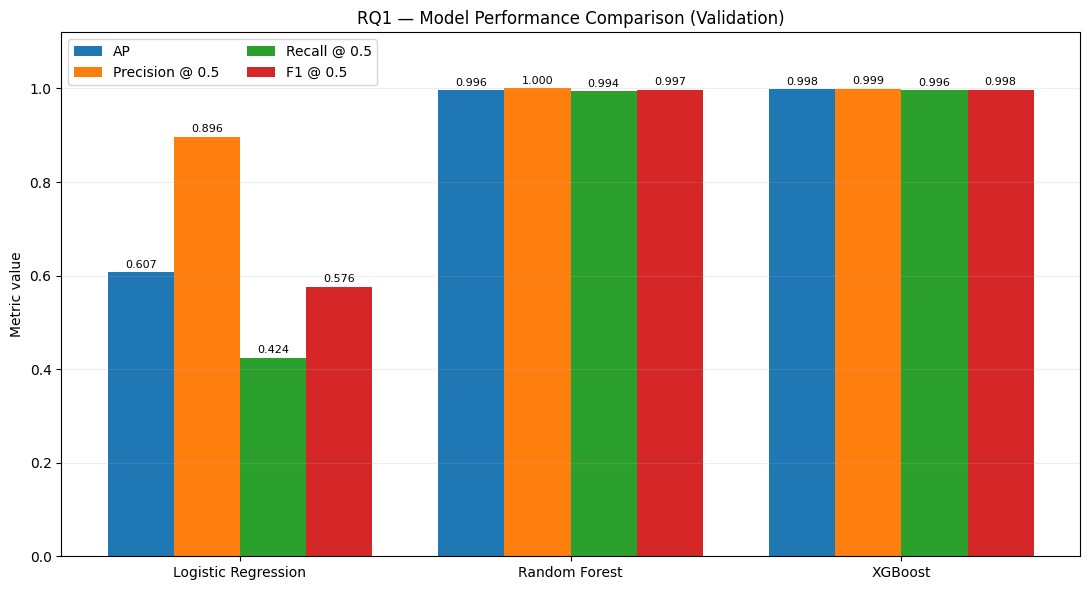

Đã lưu: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/figures/rq1_performance_comparison.png


In [ ]:
metrics_to_plot = [
    ("AP", "AP"),
    ("Precision_at_0_5", "Precision @ 0.5"),
    ("Recall_at_0_5", "Recall @ 0.5"),
    ("F1_at_0_5", "F1 @ 0.5"),
]

x = np.arange(len(MODEL_NAMES))
bar_width = 0.2
fig, ax = plt.subplots(figsize=(11, 6))
for j, (column, label) in enumerate(metrics_to_plot):
    values = comparison[column].to_numpy(dtype=float)
    assert np.isfinite(values).all(), f"Metric {column} có giá trị thiếu"
    positions = x + (j - 1.5) * bar_width
    bars = ax.bar(positions, values, width=bar_width, label=label)
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in values], padding=2, fontsize=8)

ax.set_xticks(x, [SHORT_NAMES[name] for name in MODEL_NAMES])
ax.set_ylim(0, 1.12)
ax.set_ylabel("Metric value")
ax.set_title("RQ1 — Model Performance Comparison (Validation)")
ax.legend(ncol=2)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
out = FIGURE_DIR / "rq1_performance_comparison.png"
fig.savefig(out, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Đã lưu:", out)

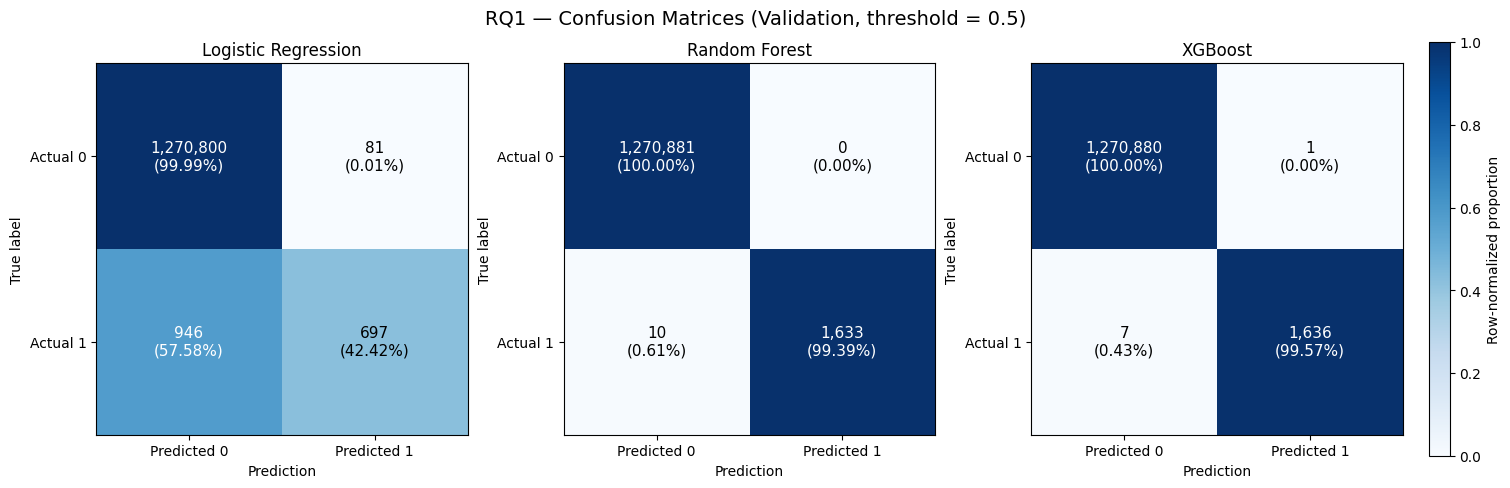

Đã lưu: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/figures/rq1_confusion_matrices.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), constrained_layout=True)
threshold = 0.5
for ax, name in zip(axes, MODEL_NAMES):
    scores = score_tables[name]["fraud_score"].to_numpy(dtype=float)
    y_pred = (scores >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    row_sum = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(cm, row_sum, out=np.zeros_like(cm, dtype=float), where=row_sum != 0)
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            count = int(cm[i, j])
            percent = cm_norm[i, j] * 100
            color = "white" if cm_norm[i, j] > 0.55 else "black"
            ax.text(j, i, f"{count:,}\n({percent:.2f}%)",
                    ha="center", va="center", fontsize=11, color=color)
    ax.set_xticks([0, 1], ["Predicted 0", "Predicted 1"])
    ax.set_yticks([0, 1], ["Actual 0", "Actual 1"])
    ax.set_xlabel("Prediction")
    ax.set_ylabel("True label")
    ax.set_title(SHORT_NAMES[name])
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, label="Row-normalized proportion")
fig.suptitle("RQ1 — Confusion Matrices (Validation, threshold = 0.5)", fontsize=14)
out = FIGURE_DIR / "rq1_confusion_matrices.png"
fig.savefig(out, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Đã lưu:", out)

In [ ]:
expected_files = [
    "rq1_pr_curves.png",
    "rq1_roc_curves.png",
    "rq1_performance_comparison.png",
    "rq1_confusion_matrices.png",
]
for filename in expected_files:
    path = FIGURE_DIR / filename
    assert path.is_file() and path.stat().st_size > 0, f"Thiếu hoặc file rỗng: {path}"
    print(f"PASS {filename} — {path.stat().st_size / 1024:.1f} KB")
print("\nHOÀN THÀNH RQ1 VISUALIZATION — tất cả hình đã lưu thành công")

PASS rq1_pr_curves.png — 93.0 KB
PASS rq1_roc_curves.png — 103.8 KB
PASS rq1_performance_comparison.png — 67.9 KB
PASS rq1_confusion_matrices.png — 120.2 KB

HOÀN THÀNH RQ1 VISUALIZATION — tất cả hình đã lưu thành công


In [ ]:
# ============================================================
# RQ1-14 — VALIDATION RESULTS INTEGRITY AUDIT
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Sử dụng lại RESULT_DIR, PP_DIR đã khai báo ở đầu notebook.
# Chỉ đọc Validation, không sử dụng Test.

comparison = pd.read_csv(
    RESULT_DIR / "rq1_comparison.csv"
).set_index("Model")

model_families = {
    "Logistic_Regression": "LR",
    "Random_Forest": "Tree",
    "XGBoost": "Tree"
}

audit_rows = []

for model_name, family in model_families.items():

    print(f"\nAuditing: {model_name}")

    # 1. Đọc scores đã lưu từ RQ1.
    score_path = (
        RESULT_DIR
        / f"{model_name}_validation_scores.parquet"
    )

    scores_df = pd.read_parquet(score_path)

    # 2. Đọc nhãn Validation trực tiếp từ file dữ liệu.
    validation_path = (
        PP_DIR
        / f"3.2.7_{family}_Validation_20pct.parquet"
    )

    y_validation = pd.read_parquet(
        validation_path,
        columns=["isFraud"]
    )["isFraud"]

    # 3. Kiểm tra index chính xác.
    assert scores_df.index.is_unique
    assert y_validation.index.is_unique

    assert len(scores_df) == len(y_validation)

    assert scores_df.index.difference(
        y_validation.index
    ).empty

    assert y_validation.index.difference(
        scores_df.index
    ).empty

    # Căn chỉnh theo index giao dịch.
    scores_df = scores_df.reindex(
        y_validation.index
    )

    # 4. Kiểm tra nhãn đã lưu có khớp với Validation.
    assert np.array_equal(
        scores_df["isFraud"].to_numpy(),
        y_validation.to_numpy()
    ), f"{model_name}: Target không khớp!"

    y_true = y_validation.to_numpy(dtype=int)

    scores = scores_df[
        "fraud_score"
    ].to_numpy(dtype=float)

    assert np.isfinite(scores).all()
    assert ((scores >= 0) & (scores <= 1)).all()

    # 5. Tính lại toàn bộ metrics.
    y_pred = (scores >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    recalculated = {
        "AP": average_precision_score(
            y_true, scores
        ),
        "ROC_AUC": roc_auc_score(
            y_true, scores
        ),
        "Precision_at_0_5": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall_at_0_5": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1_at_0_5": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn)
    }

    # 6. So sánh với bảng metrics RQ1 đã lưu.
    for metric, value in recalculated.items():
        expected = comparison.loc[
            model_name, metric
        ]

        assert np.isclose(
            value, expected,
            rtol=1e-8,
            atol=1e-8
        ), (
            f"{model_name}: "
            f"{metric} không khớp!"
        )

    audit_rows.append({
        "Model": model_name,
        **recalculated,
        "Audit_Status": "PASS"
    })

    print("PASS: Index, target và metrics khớp.")

# 7. Xuất báo cáo kiểm toán.
audit_report = pd.DataFrame(audit_rows)

audit_path = (
    RESULT_DIR / "rq1_audit_report.csv"
)

audit_report.to_csv(
    audit_path,
    index=False
)

display(audit_report)

print("\nHOÀN THÀNH RQ1 AUDIT")
print("Saved:", audit_path)


Auditing: Logistic_Regression
PASS: Index, target và metrics khớp.

Auditing: Random_Forest
PASS: Index, target và metrics khớp.

Auditing: XGBoost
PASS: Index, target và metrics khớp.


,Model,AP,ROC_AUC,Precision_at_0_5,Recall_at_0_5,F1_at_0_5,TP,FP,FN,TN,Audit_Status
0,Logistic_Regression,0.606986,0.981857,0.895887,0.424224,0.575795,697,81,946,1270800,PASS
1,Random_Forest,0.996064,0.999735,1.000000,0.993914,0.996947,1633,0,10,1270881,PASS
2,XGBoost,0.997863,0.999920,0.999389,0.995740,0.997561,1636,1,7,1270880,PASS



HOÀN THÀNH RQ1 AUDIT
Saved: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/results/rq1_audit_report.csv


### RQ1-15. Feature Ablation Analysis

**Objective:** Evaluate the sensitivity of XGBoost performance to engineered balance-discrepancy features and post-transaction balance information.

**Input:** Preprocessed Tree Train (60%) and Validation (20%) datasets, the baseline XGBoost configuration, and saved RQ1 evaluation results.

**Experimental Design:** Compare three feature configurations: (1) Full Features, (2) Without Engineered Features, and (3) Without Engineered and Post-Transaction Balance Features. The original XGBoost baseline is reused without retraining; the two reduced-feature configurations are trained separately using the same hyperparameters.

**Evaluation:** Average Precision (AP), ROC-AUC, Precision, Recall, F1-score, False Positives (FP), and False Negatives (FN). Threshold-dependent metrics use the reference threshold of 0.5.

**Output:** `RQ1/results/rq1_feature_ablation.csv` and `RQ1/figures/rq1_feature_ablation.png`.

**Methodological Considerations:** All experiments use the existing Train and Validation partitions. The Test set remains untouched. Changes in model performance indicate sensitivity to feature removal, but do not independently demonstrate data leakage or causal importance. This experiment examines the baseline XGBoost configuration rather than conducting additional hyperparameter optimization.

In [ ]:

# ============================================================
# RQ1-15A — FEATURE ABLATION ANALYSIS
# ============================================================

import gc
import time
import numpy as np
import pandas as pd

from sklearn.base import clone
from IPython.display import display

# ------------------------------------------------------------
# STEP 1. Khai báo đường dẫn dữ liệu
# ------------------------------------------------------------
# Chỉ sử dụng Tree Train và Tree Validation.
# Không truy cập tập Test.

train_path = PP_DIR / "3.2.7_Tree_Train_60pct.parquet"
val_path = PP_DIR / "3.2.7_Tree_Validation_20pct.parquet"

comparison_path = RESULT_DIR / "rq1_comparison.csv"
output_path = RESULT_DIR / "rq1_feature_ablation.csv"

for path in [train_path, val_path, comparison_path]:
    assert path.is_file(), f"File không tồn tại: {path}"

# ------------------------------------------------------------
# STEP 2. Đọc dữ liệu và tách X, y
# ------------------------------------------------------------

train_df = pd.read_parquet(train_path)
val_df = pd.read_parquet(val_path)

TARGET = "isFraud"

assert TARGET in train_df.columns
assert TARGET in val_df.columns

assert train_df.columns.equals(val_df.columns)
assert train_df.index.is_unique
assert val_df.index.is_unique
assert train_df.index.intersection(val_df.index).empty

X_train = train_df.drop(columns=[TARGET])
y_train = train_df[TARGET].astype("int8")

X_val = val_df.drop(columns=[TARGET])
y_val = val_df[TARGET].astype("int8")

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Fraud Train:", int(y_train.sum()))
print("Fraud Validation:", int(y_val.sum()))

# ------------------------------------------------------------
# STEP 3. Xác định các nhóm features cần loại bỏ
# ------------------------------------------------------------
# Engineered features:
#   errorbalanceOrig
#   errorbalanceDest
#
# Post-transaction balance:
#   newbalanceOrig
#   newbalanceDest
#
# Các tên được đối chiếu với schema thực tế của Parquet.

engineered_features = [
    "errorbalanceOrig",
    "errorbalanceDest"
]

post_balance_features = [
    "newbalanceOrig",
    "newbalanceDest"
]

# Trong trường hợp sklearn tạo tiền tố như num__,
# tìm đúng cột tương ứng theo tên feature gốc.
def resolve_feature_columns(columns, raw_names):
    resolved = []

    for raw_name in raw_names:
        matches = [
            col for col in columns
            if col == raw_name
            or col.endswith("__" + raw_name)
        ]

        assert len(matches) == 1, (
            f"Không xác định được duy nhất feature "
            f"'{raw_name}'. Matches: {matches}"
        )

        resolved.append(matches[0])

    return resolved

engineered_cols = resolve_feature_columns(
    X_train.columns,
    engineered_features
)

post_balance_cols = resolve_feature_columns(
    X_train.columns,
    post_balance_features
)

print("\nEngineered columns:", engineered_cols)
print("Post-balance columns:", post_balance_cols)

# ------------------------------------------------------------
# STEP 4. Xây dựng ba feature configurations
# ------------------------------------------------------------

all_features = list(X_train.columns)

feature_sets = {
    "Full_Features": all_features,

    "Without_Engineered": [
        col for col in all_features
        if col not in engineered_cols
    ],

    "Without_Engineered_and_PostBalance": [
        col for col in all_features
        if col not in (
            engineered_cols + post_balance_cols
        )
    ]
}

for config_name, columns in feature_sets.items():
    print(f"{config_name}: {len(columns)} features")

# ------------------------------------------------------------
# STEP 5. Đọc kết quả XGBoost baseline từ RQ1
# ------------------------------------------------------------
# Full Features đã huấn luyện và kiểm toán PASS.
# Không cần train lại cấu hình này.

comparison = pd.read_csv(comparison_path)

baseline_rows = comparison.loc[
    comparison["Model"] == "XGBoost"
]

assert len(baseline_rows) == 1, (
    "Không tìm thấy đúng một dòng XGBoost baseline."
)

baseline = baseline_rows.iloc[0]

results = [{
    "Configuration": "Full_Features",
    "Num_Features": len(all_features),
    "AP": float(baseline["AP"]),
    "ROC_AUC": float(baseline["ROC_AUC"]),
    "Precision": float(baseline["Precision_at_0_5"]),
    "Recall": float(baseline["Recall_at_0_5"]),
    "F1": float(baseline["F1_at_0_5"]),
    "TP": int(baseline["TP"]),
    "FP": int(baseline["FP"]),
    "FN": int(baseline["FN"]),
    "TN": int(baseline["TN"]),
    "Training_Seconds": float(
        baseline["Train_Seconds"]
    )
}]

# ------------------------------------------------------------
# STEP 6. Huấn luyện các cấu hình giảm features
# ------------------------------------------------------------
# Chỉ thay đổi feature set.
# Thuật toán, hyperparameters, Train/Validation
# và threshold tham chiếu đều được giữ nguyên.

for config_name in [
    "Without_Engineered",
    "Without_Engineered_and_PostBalance"
]:

    selected_columns = feature_sets[config_name]

    print("\n" + "=" * 55)
    print("Training configuration:", config_name)
    print("Number of features:", len(selected_columns))
    print("=" * 55)

    # Clone estimator chưa fit từ source RQ1.
    model = clone(
        MODEL_CONFIGS["XGBoost"]["estimator"]
    )

    start = time.perf_counter()

    model.fit(
        X_train[selected_columns],
        y_train
    )

    training_seconds = (
        time.perf_counter() - start
    )

    # Dự đoán trên Validation chưa resampling.
    validation_scores = model.predict_proba(
        X_val[selected_columns]
    )[:, 1]

    # Sử dụng đúng hàm metrics của RQ1.
    metrics = evaluate_on_validation(
        y_val,
        validation_scores,
        THRESHOLD_REFERENCE
    )

    row = {
        "Configuration": config_name,
        "Num_Features": len(selected_columns),
        "AP": metrics["AP"],
        "ROC_AUC": metrics["ROC_AUC"],
        "Precision": metrics["Precision_at_0_5"],
        "Recall": metrics["Recall_at_0_5"],
        "F1": metrics["F1_at_0_5"],
        "TP": metrics["TP"],
        "FP": metrics["FP"],
        "FN": metrics["FN"],
        "TN": metrics["TN"],
        "Training_Seconds": round(
            training_seconds, 2
        )
    }

    results.append(row)

    # Lưu checkpoint sau mỗi cấu hình.
    # Nếu Colab ngắt kết nối, kết quả đã hoàn thành
    # vẫn được lưu tại rq1_feature_ablation.csv.
    temp_df = pd.DataFrame(results)

    temp_df["AP_Drop_vs_Full"] = (
        float(baseline["AP"]) - temp_df["AP"]
    )

    temp_df.to_csv(output_path, index=False)

    print(
        f"AP = {metrics['AP']:.6f} | "
        f"F1 = {metrics['F1_at_0_5']:.6f} | "
        f"FP = {metrics['FP']} | "
        f"FN = {metrics['FN']}"
    )

    print("Checkpoint saved:", output_path)

    del model, validation_scores
    gc.collect()

# ------------------------------------------------------------
# STEP 7. Hiển thị và lưu bảng tổng hợp
# ------------------------------------------------------------

ablation_df = pd.DataFrame(results)

ablation_df["AP_Drop_vs_Full"] = (
    float(baseline["AP"]) - ablation_df["AP"]
)

ablation_df.to_csv(
    output_path,
    index=False
)

display(ablation_df.round(6))

print("\nPASS: FEATURE ABLATION COMPLETED")
print("Saved:", output_path)

# Giải phóng bộ nhớ.
del train_df, val_df
del X_train, y_train, X_val, y_val
gc.collect()


Train: (3817572, 13)
Validation: (1272524, 13)
Fraud Train: 4928
Fraud Validation: 1643

Engineered columns: ['errorbalanceOrig', 'errorbalanceDest']
Post-balance columns: ['newbalanceOrig', 'newbalanceDest']
Full_Features: 13 features
Without_Engineered: 11 features
Without_Engineered_and_PostBalance: 9 features

Training configuration: Without_Engineered
Number of features: 11
AP = 0.962956 | F1 = 0.899870 | FP = 49 | FN = 259
Checkpoint saved: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/results/rq1_feature_ablation.csv

Training configuration: Without_Engineered_and_PostBalance
Number of features: 9
AP = 0.880644 | F1 = 0.795989 | FP = 98 | FN = 492
Checkpoint saved: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/results/rq1_feature_ablation.csv


,Configuration,Num_Features,AP,ROC_AUC,Precision,Recall,F1,TP,FP,FN,TN,Training_Seconds,AP_Drop_vs_Full
0,Full_Features,13,0.997863,0.999920,0.999389,0.995740,0.997561,1636,1,7,1270880,69.99,0.000000
1,Without_Engineered,11,0.962956,0.999826,0.965806,0.842362,0.899870,1384,49,259,1270832,69.97,0.034908
2,Without_Engineered_and_PostBalance,9,0.880644,0.998139,0.921537,0.700548,0.795989,1151,98,492,1270783,65.83,0.117220



PASS: FEATURE ABLATION COMPLETED
Saved: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/results/rq1_feature_ablation.csv


0

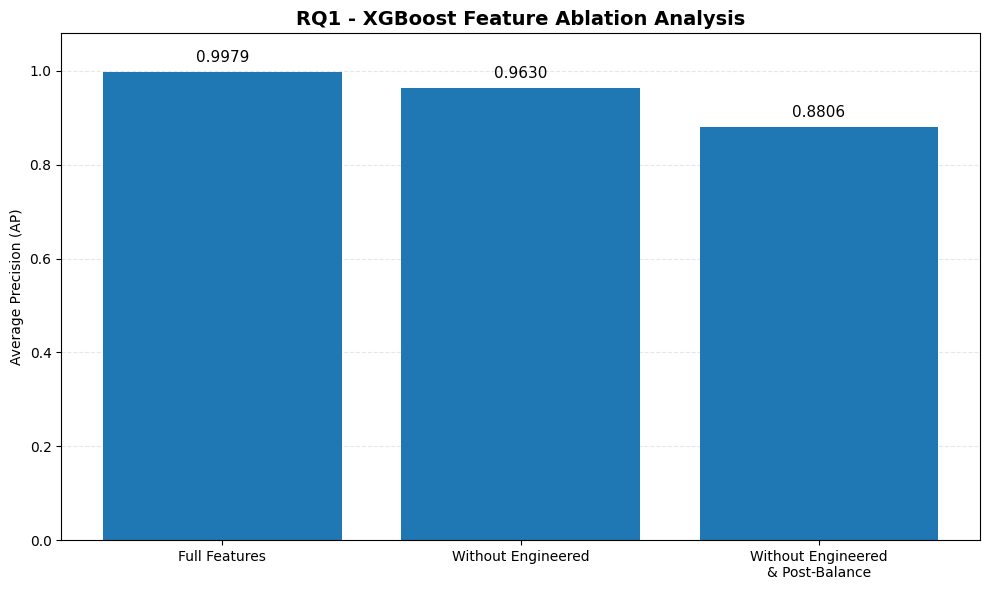

PASS: Figure saved successfully.
Saved: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/figures/rq1_feature_ablation.png


In [ ]:

# ============================================================
# RQ1-15B — FEATURE ABLATION VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# STEP 1. Đọc kết quả đã lưu
# ------------------------------------------------------------

ablation_path = (
    RESULT_DIR / "rq1_feature_ablation.csv"
)

assert ablation_path.is_file(), (
    "Chưa tìm thấy kết quả Feature Ablation."
)

ablation_df = pd.read_csv(ablation_path)

required_configs = {
    "Full_Features",
    "Without_Engineered",
    "Without_Engineered_and_PostBalance"
}

assert set(ablation_df["Configuration"]) == required_configs, (
    "Chưa hoàn thành đủ ba configurations."
)

# Sắp xếp đúng thứ tự thí nghiệm.
order = [
    "Full_Features",
    "Without_Engineered",
    "Without_Engineered_and_PostBalance"
]

plot_df = (
    ablation_df
    .set_index("Configuration")
    .loc[order]
    .reset_index()
)

# ------------------------------------------------------------
# STEP 2. Vẽ biểu đồ Average Precision
# ------------------------------------------------------------

labels = [
    "Full Features",
    "Without Engineered",
    "Without Engineered\n& Post-Balance"
]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    labels,
    plot_df["AP"]
)

ax.set_title(
    "RQ1 - XGBoost Feature Ablation Analysis",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Average Precision (AP)")
ax.set_ylim(0, 1.08)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

# Hiển thị giá trị AP phía trên cột.
for bar, ap in zip(bars, plot_df["AP"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{ap:.4f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()

# ------------------------------------------------------------
# STEP 3. Lưu biểu đồ
# ------------------------------------------------------------

figure_path = (
    FIGURE_DIR / "rq1_feature_ablation.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

assert figure_path.is_file()
assert figure_path.stat().st_size > 0

print("PASS: Figure saved successfully.")
print("Saved:", figure_path)


### RQ1-16. XGBoost Feature Importance Analysis

**Objective:** Examine the relative importance of input features within the trained XGBoost baseline model.

**Input:** The saved `XGBoost.joblib` estimator from RQ1.

**Procedure:** Extract gain-based feature importance, associate each importance value with its corresponding preprocessed feature, rank the features, and generate a horizontal bar chart.

**Output:** `rq1_xgboost_feature_importance.csv` and `rq1_xgboost_feature_importance.png`.

**Methodological considerations:** Gain-based importance summarizes improvements in the model's splitting objective attributed to each feature. It does not establish causal importance, independently prove data leakage, or measure predictive performance changes after feature removal. Findings should be interpreted alongside the Feature Ablation Analysis in RQ1-15. No retraining or Test-set evaluation is performed.

Number of features: 13
Features: [np.str_('step'), np.str_('amount'), np.str_('oldbalanceOrg'), np.str_('newbalanceOrig'), np.str_('oldbalanceDest'), np.str_('newbalanceDest'), np.str_('errorbalanceOrig'), np.str_('errorbalanceDest'), np.str_('type_CASH_IN'), np.str_('type_CASH_OUT'), np.str_('type_DEBIT'), np.str_('type_PAYMENT'), np.str_('type_TRANSFER')]

XGBoost Feature Importance:


,Rank,Feature,Gain,Normalized_Gain
0,1,oldbalanceDest,2492.398438,0.417823
1,2,errorbalanceOrig,901.095398,0.151059
2,3,amount,791.929260,0.132758
3,4,oldbalanceOrg,696.095032,0.116693
4,5,errorbalanceDest,551.737305,0.092493
5,6,type_TRANSFER,254.683258,0.042695
6,7,type_CASH_OUT,103.495255,0.017350
7,8,newbalanceDest,83.493568,0.013997
8,9,step,44.902561,0.007527
9,10,newbalanceOrig,31.198370,0.005230


Saved CSV: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/results/rq1_xgboost_feature_importance.csv


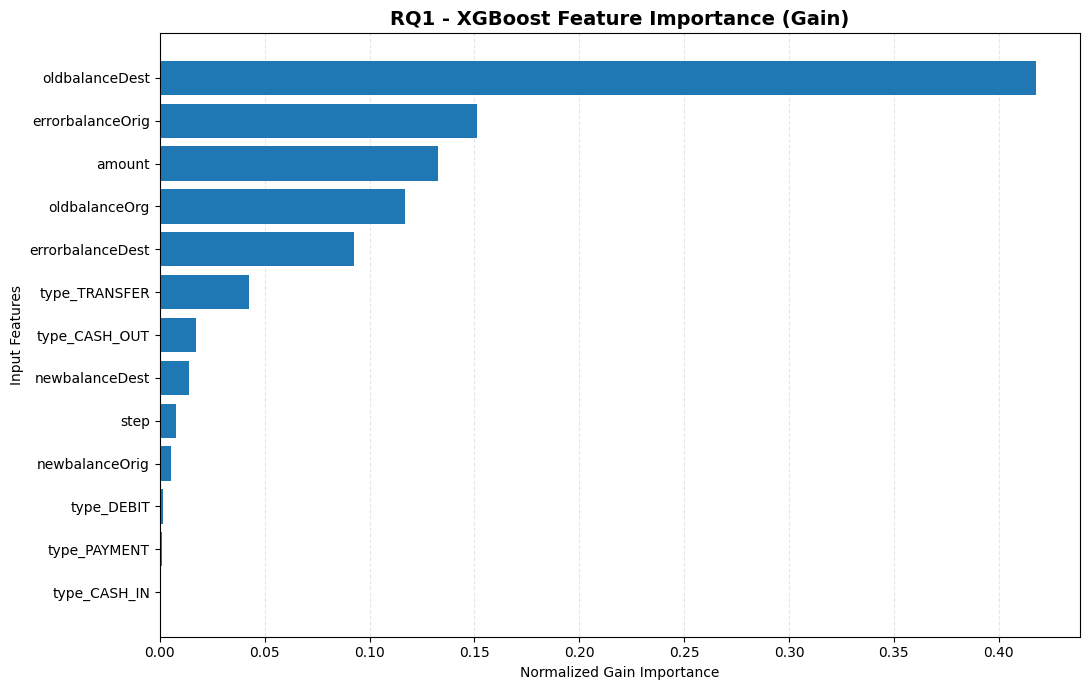


PASS: FEATURE IMPORTANCE COMPLETED
CSV: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/results/rq1_xgboost_feature_importance.csv
Figure: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/figures/rq1_xgboost_feature_importance.png


In [ ]:

# ============================================================
# RQ1-16 — XGBOOST FEATURE IMPORTANCE ANALYSIS
# ============================================================

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# ------------------------------------------------------------
# STEP 1. Xác định các đường dẫn đã tạo trong RQ1
# ------------------------------------------------------------
# Sử dụng MODEL_DIR, RESULT_DIR, FIGURE_DIR có sẵn.
# Không tạo thư mục mới và không đọc Test.

model_path = MODEL_DIR / "XGBoost.joblib"

csv_path = (
    RESULT_DIR / "rq1_xgboost_feature_importance.csv"
)

figure_path = (
    FIGURE_DIR / "rq1_xgboost_feature_importance.png"
)

assert model_path.is_file(), (
    f"Không tìm thấy XGBoost model: {model_path}"
)

# ------------------------------------------------------------
# STEP 2. Nạp XGBoost baseline đã huấn luyện
# ------------------------------------------------------------

xgb_model = joblib.load(model_path)

# Kiểm tra đây là XGBoost có booster đã được fit.
booster = xgb_model.get_booster()

# Sử dụng tên feature thực tế đã lưu trong model.
feature_names = list(xgb_model.feature_names_in_)

print("Number of features:", len(feature_names))
print("Features:", feature_names)

# ------------------------------------------------------------
# STEP 3. Trích xuất Gain-based Feature Importance
# ------------------------------------------------------------
# Gain phản ánh mức cải thiện trung bình của splitting
# objective khi một feature được dùng để chia cây.
#
# get_score() có thể bỏ qua feature không được sử dụng.
# Vì vậy, mặc định importance = 0 cho các feature đó.

gain_scores = booster.get_score(
    importance_type="gain"
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Gain": [
        float(gain_scores.get(feature, 0.0))
        for feature in feature_names
    ]
})

# Chuẩn hóa để dễ so sánh tỷ trọng giữa các features.
total_gain = importance_df["Gain"].sum()

assert total_gain > 0, (
    "Không trích xuất được Gain Importance."
)

importance_df["Normalized_Gain"] = (
    importance_df["Gain"] / total_gain
)

importance_df = (
    importance_df
    .sort_values("Normalized_Gain", ascending=False)
    .reset_index(drop=True)
)

importance_df.insert(
    0, "Rank",
    np.arange(1, len(importance_df) + 1)
)

# ------------------------------------------------------------
# STEP 4. Lưu bảng Feature Importance
# ------------------------------------------------------------

importance_df.to_csv(csv_path, index=False)

print("\nXGBoost Feature Importance:")
display(importance_df.round(6))

print("Saved CSV:", csv_path)

# ------------------------------------------------------------
# STEP 5. Vẽ biểu đồ Feature Importance
# ------------------------------------------------------------

plot_df = importance_df.sort_values(
    "Normalized_Gain", ascending=True
)

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    plot_df["Feature"],
    plot_df["Normalized_Gain"]
)

ax.set_title(
    "RQ1 - XGBoost Feature Importance (Gain)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Normalized Gain Importance")
ax.set_ylabel("Input Features")

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# STEP 6. Xác nhận output
# ------------------------------------------------------------

assert csv_path.is_file()
assert figure_path.is_file()

assert csv_path.stat().st_size > 0
assert figure_path.stat().st_size > 0

print("\nPASS: FEATURE IMPORTANCE COMPLETED")
print("CSV:", csv_path)
print("Figure:", figure_path)


### RQ1-17. Final Model Selection and Research Conclusion

**Objective:** Finalize the baseline model selection for subsequent class-imbalance experiments in RQ2.

**Input:** `rq1_comparison.csv`, `rq1_audit_report.csv`, `rq1_feature_ablation.csv`, and the trained baseline model artifacts.

**Selection Criterion:** Select the classifier with the highest Average Precision (AP) on the Validation set, as specified in the RQ1 experimental protocol. Threshold-dependent metrics are considered supporting evidence.

**Procedure:** Verify the integrity audit, rank all three models by AP, confirm the selected model artifact, record the selected preprocessing family, and preserve the selection rationale and experimental limitations.

**Output:** `RQ1/results/selected_model.json` and `RQ1/results/rq1_model_selection_summary.csv`.

**Methodological Considerations:** The selection is limited to the evaluated baseline configurations. The held-out Test set remains untouched. The feature ablation experiment indicates sensitivity to balance-related inputs but does not independently establish leakage or real-world generalizability. The selected model and feature set remain unchanged for the primary RQ2 comparison.

In [ ]:

# ============================================================
# RQ1-17 — FINAL MODEL SELECTION
# ============================================================

import json
import numpy as np
import pandas as pd
import joblib

from IPython.display import display

# ------------------------------------------------------------
# STEP 1. Khai báo các output đã có của RQ1
# ------------------------------------------------------------

comparison_path = (
    RESULT_DIR / "rq1_comparison.csv"
)

audit_path = (
    RESULT_DIR / "rq1_audit_report.csv"
)

ablation_path = (
    RESULT_DIR / "rq1_feature_ablation.csv"
)

selection_path = (
    RESULT_DIR / "selected_model.json"
)

summary_path = (
    RESULT_DIR / "rq1_model_selection_summary.csv"
)

for path in [
    comparison_path,
    audit_path,
    ablation_path
]:
    assert path.is_file(), (
        f"Thiếu kết quả RQ1: {path}"
    )

# ------------------------------------------------------------
# STEP 2. Nạp và kiểm tra bảng kết quả
# ------------------------------------------------------------

comparison = pd.read_csv(comparison_path)
audit = pd.read_csv(audit_path)
ablation = pd.read_csv(ablation_path)

expected_models = {
    "Logistic_Regression",
    "Random_Forest",
    "XGBoost"
}

assert set(comparison["Model"]) == expected_models
assert comparison["Model"].is_unique

assert set(audit["Model"]) == expected_models
assert audit["Model"].is_unique

assert audit["Audit_Status"].eq("PASS").all(), (
    "Có mô hình chưa vượt qua RQ1 Integrity Audit."
)

# Kiểm tra các giá trị AP trong khoảng hợp lệ.
assert comparison["AP"].notna().all()

assert comparison["AP"].between(0, 1).all()

# Đối chiếu AP trong bảng so sánh và báo cáo audit.
merged = comparison[["Model", "AP"]].merge(
    audit[["Model", "AP"]],
    on="Model",
    suffixes=("_comparison", "_audit"),
    validate="one_to_one"
)

assert np.allclose(
    merged["AP_comparison"],
    merged["AP_audit"],
    rtol=1e-8,
    atol=1e-8
), "AP trong comparison và audit không khớp."

# ------------------------------------------------------------
# STEP 3. Xác nhận kết quả Feature Ablation
# ------------------------------------------------------------

required_configs = {
    "Full_Features",
    "Without_Engineered",
    "Without_Engineered_and_PostBalance"
}

assert set(ablation["Configuration"]) == required_configs
assert ablation["Configuration"].is_unique

full_ap = float(
    ablation.loc[
        ablation["Configuration"] == "Full_Features",
        "AP"
    ].iloc[0]
)

xgb_ap = float(
    comparison.loc[
        comparison["Model"] == "XGBoost",
        "AP"
    ].iloc[0]
)

assert np.isclose(
    full_ap,
    xgb_ap,
    rtol=1e-8,
    atol=1e-8
), "Full-feature XGBoost AP không khớp RQ1."

# ------------------------------------------------------------
# STEP 4. Xếp hạng mô hình theo Average Precision
# ------------------------------------------------------------
# AP là metric chính.
# ROC-AUC được dùng để sắp xếp khi AP bằng nhau
# trong độ chính xác được lưu, không phải tiêu chí
# đánh giá thay thế AP.

ranking = comparison.sort_values(
    by=["AP", "ROC_AUC"],
    ascending=[False, False]
).reset_index(drop=True)

ranking.insert(
    0, "Rank",
    np.arange(1, len(ranking) + 1)
)

selected_name = str(ranking.iloc[0]["Model"])
selected_ap = float(ranking.iloc[0]["AP"])

print("RQ1 Model Ranking:")
display(ranking)

print("\nSelected Model:", selected_name)
print("Selection AP:", round(selected_ap, 6))

# ------------------------------------------------------------
# STEP 5. Xác định preprocessing family
# ------------------------------------------------------------

family_map = {
    "Logistic_Regression": "LR",
    "Random_Forest": "Tree",
    "XGBoost": "Tree"
}

selected_family = family_map[selected_name]

# Chỉ lấy file mô hình đã fit.
selected_model_path = (
    MODEL_DIR / f"{selected_name}.joblib"
)

assert selected_model_path.is_file(), (
    f"Không tìm thấy trained model: {selected_model_path}"
)

# Kiểm tra khả năng đọc artifact.
selected_estimator = joblib.load(
    selected_model_path
)

# Dữ liệu được fit phải có 13 features đã preprocessing.
num_features = int(
    selected_estimator.n_features_in_
)

assert num_features == 13, (
    f"Unexpected feature count: {num_features}"
)

# ------------------------------------------------------------
# STEP 6. Tính chênh lệch với mô hình đứng thứ hai
# ------------------------------------------------------------

runner_up = str(ranking.iloc[1]["Model"])

runner_up_ap = float(
    ranking.iloc[1]["AP"]
)

ap_difference = selected_ap - runner_up_ap

print("\nRunner-up:", runner_up)
print("AP difference:", round(ap_difference, 6))

# ------------------------------------------------------------
# STEP 7. Ghi nhận kết luận Feature Ablation
# ------------------------------------------------------------

ablation_ap = {
    str(row["Configuration"]): float(row["AP"])
    for _, row in ablation.iterrows()
}

ap_drop_engineered = (
    ablation_ap["Full_Features"]
    - ablation_ap["Without_Engineered"]
)

ap_drop_post_balance_additional = (
    ablation_ap["Without_Engineered"]
    - ablation_ap[
        "Without_Engineered_and_PostBalance"
    ]
)

# ------------------------------------------------------------
# STEP 8. Xây dựng cấu hình bàn giao cho RQ2
# ------------------------------------------------------------

selection = {
    "research_question": "RQ1",
    "selected_model": selected_name,
    "preprocessing_family": selected_family,

    "selection_metric": "AP",
    "selection_dataset": "Validation_20pct",
    "selection_metric_value": selected_ap,

    "runner_up_model": runner_up,
    "runner_up_ap": runner_up_ap,
    "ap_difference_vs_runner_up": ap_difference,

    "baseline_model_path": str(
        selected_model_path
    ),

    "train_data_path": str(
        PP_DIR /
        f"3.2.7_{selected_family}_Train_60pct.parquet"
    ),

    "validation_data_path": str(
        PP_DIR /
        f"3.2.7_{selected_family}_Validation_20pct.parquet"
    ),

    "target_column": "isFraud",
    "num_features": num_features,

    "reference_threshold": 0.5,
    "random_state": 42,

    "imbalance_handling_in_RQ1": "Original",

    "feature_set": "Full_Features",

    "feature_ablation": {
        "ap_without_engineered": ablation_ap[
            "Without_Engineered"
        ],
        "ap_without_engineered_and_post_balance":
            ablation_ap[
                "Without_Engineered_and_PostBalance"
            ],
        "ap_drop_without_engineered":
            ap_drop_engineered,
        "additional_ap_drop_without_post_balance":
            ap_drop_post_balance_additional
    },

    "test_used_for_selection": False,

    "selection_rationale": (
        "Highest Average Precision on the predefined "
        "Validation split among the three evaluated "
        "baseline configurations."
    ),

    "limitations": [
        "Evaluation uses a simulated fraud dataset.",
        "Performance depends partly on balance-related features.",
        "Generalization to real-world banking transactions "
        "has not been established.",
        "Random stratified splitting does not constitute "
        "temporal out-of-sample validation.",
        "Baseline hyperparameters were not exhaustively tuned.",
        "The AP difference from the runner-up has not "
        "been tested for statistical significance."
    ]
}

# ------------------------------------------------------------
# STEP 9. Lưu selected_model.json
# ------------------------------------------------------------

with open(
    selection_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        selection,
        file,
        ensure_ascii=False,
        indent=2
    )

# ------------------------------------------------------------
# STEP 10. Lưu bảng xếp hạng mô hình
# ------------------------------------------------------------

ranking.to_csv(
    summary_path,
    index=False
)

# ------------------------------------------------------------
# STEP 11. Kiểm tra file JSON sau khi ghi
# ------------------------------------------------------------

with open(
    selection_path,
    "r",
    encoding="utf-8"
) as file:

    saved_selection = json.load(file)

assert saved_selection["selected_model"] == selected_name

assert saved_selection[
    "preprocessing_family"
] == selected_family

assert saved_selection[
    "test_used_for_selection"
] is False

print("\n" + "=" * 55)
print("RQ1 MODEL SELECTION COMPLETED")
print("=" * 55)

print("Selected model:", selected_name)
print("Preprocessing:", selected_family)
print("Validation AP:", round(selected_ap, 6))
print("Selected model path:", selected_model_path)

print("\nSaved outputs:")
print("1.", selection_path)
print("2.", summary_path)

print("\nPASS: RQ1 is ready for RQ2.")


RQ1 Model Ranking:


,Rank,Model,Family,Train_Rows,Validation_Rows,Fraud_Train,Fraud_Validation,Train_Seconds,AP,ROC_AUC,Accuracy,Precision_at_0_5,Recall_at_0_5,F1_at_0_5,TP,FP,FN,TN
0,1,XGBoost,Tree,3817572,1272524,4928,1643,69.99,0.997863,0.999920,0.999994,0.999389,0.995740,0.997561,1636,1,7,1270880
1,2,Random_Forest,Tree,3817572,1272524,4928,1643,503.39,0.996064,0.999735,0.999992,1.000000,0.993914,0.996947,1633,0,10,1270881
2,3,Logistic_Regression,LR,3817572,1272524,4928,1643,7.63,0.606986,0.981857,0.999193,0.895887,0.424224,0.575795,697,81,946,1270800



Selected Model: XGBoost
Selection AP: 0.997863

Runner-up: Random_Forest
AP difference: 0.0018

RQ1 MODEL SELECTION COMPLETED
Selected model: XGBoost
Preprocessing: Tree
Validation AP: 0.997863
Selected model path: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/models/XGBoost.joblib

Saved outputs:
1. /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/results/selected_model.json
2. /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ1/results/rq1_model_selection_summary.csv

PASS: RQ1 is ready for RQ2.
